<a href="https://colab.research.google.com/github/mideade247/ProjectITC/blob/main/CV_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import ultralytics
import cv2
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:

video_info = [
    {'path': '/content/drive/MyDrive/Dataset/day_1.mp4', 'name': 'day1'},
    {'path': '/content/drive/MyDrive/Dataset/day_2.mp4', 'name': 'day2'},
    {'path': '/content/drive/MyDrive/Dataset/day_3.mp4', 'name': 'day3'}
]

output_folder = 'frames'
os.makedirs(output_folder, exist_ok=True)

interval_seconds = 30  # Time interval between frames to save

for vid in video_info:
    cap = cv2.VideoCapture(vid['path'])
    if not cap.isOpened():
        print(f"Failed to open {vid['path']}")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_seconds = frame_count / fps

    print(f"{vid['name']}: {fps:.2f} fps, {frame_count} frames, {duration_seconds:.2f} seconds recorded")

    timestamps_to_capture = [t for t in range(0, int(duration_seconds),interval_seconds)]

    for timestamp in timestamps_to_capture:
        frame_number = int(fps * timestamp)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)  # Seek to the specific frame
        ret, frame = cap.read()
        if ret:
            frame_file = f"{output_folder}/{vid['name']}_time_{timestamp}s.jpg"
            if not cv2.imwrite(frame_file, frame):
                print(f"Failed to write frame at {timestamp} seconds for {vid['name']}")
        else:
            print(f"Could not retrieve frame at {timestamp} seconds for {vid['name']}")

    cap.release()
    print(f"Finished processing {vid['name']}.\n")


day1: 25.00 fps, 727515 frames, 29100.60 seconds recorded
Finished processing day1.

day2: 25.00 fps, 940578 frames, 37623.12 seconds recorded
Finished processing day2.

day3: 25.00 fps, 1079987 frames, 43199.48 seconds recorded
Finished processing day3.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Showing frames for day1:


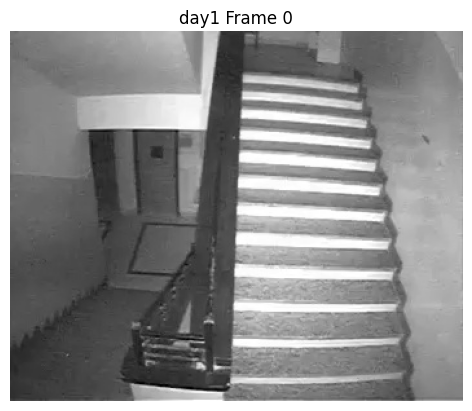

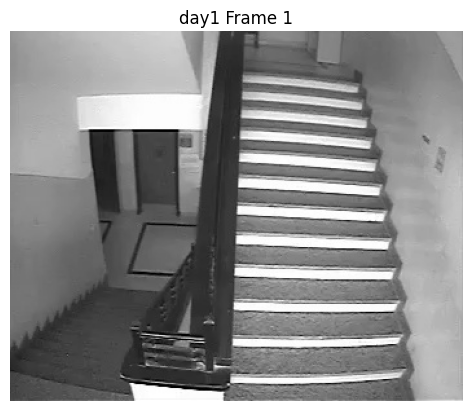

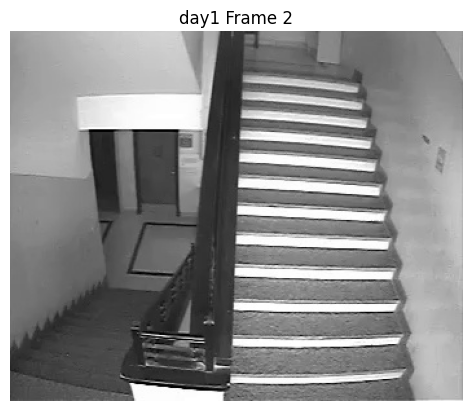

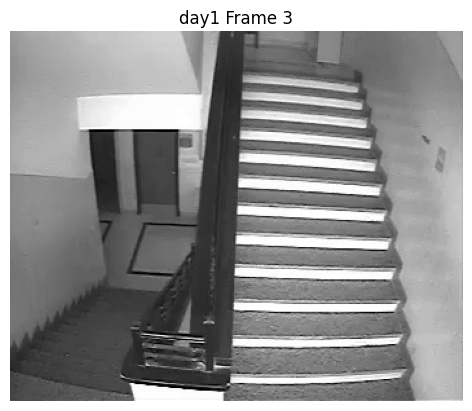

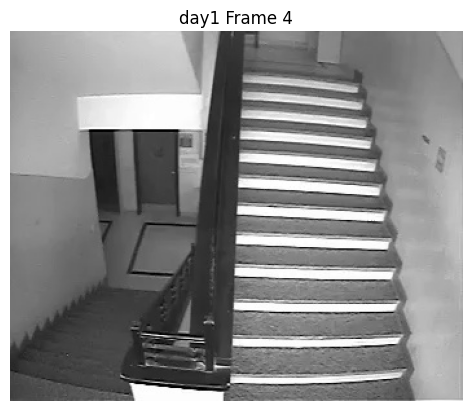

Showing frames for day2:


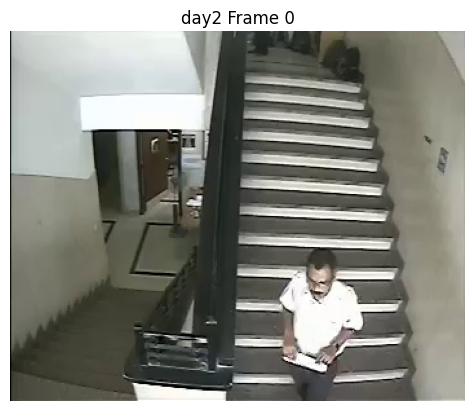

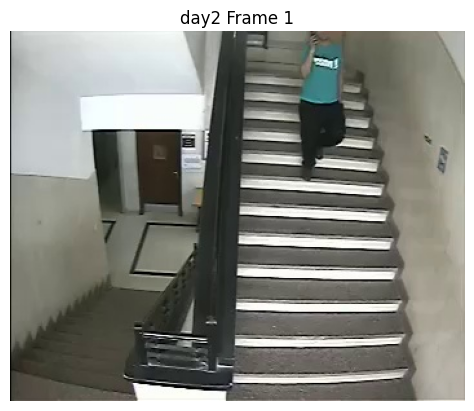

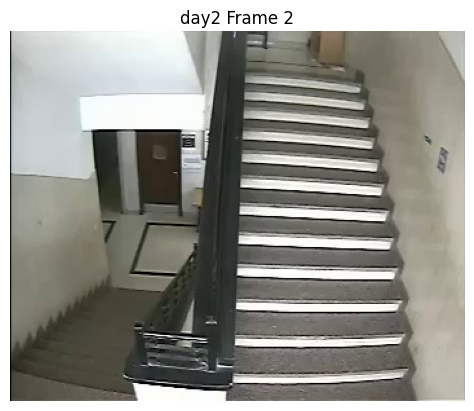

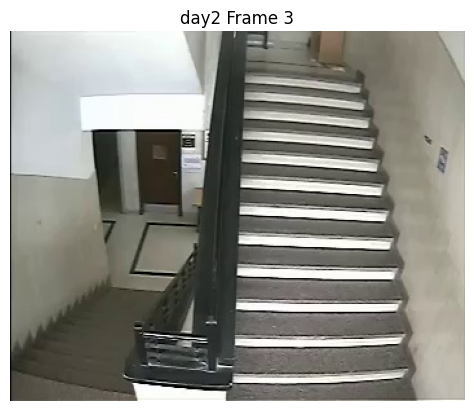

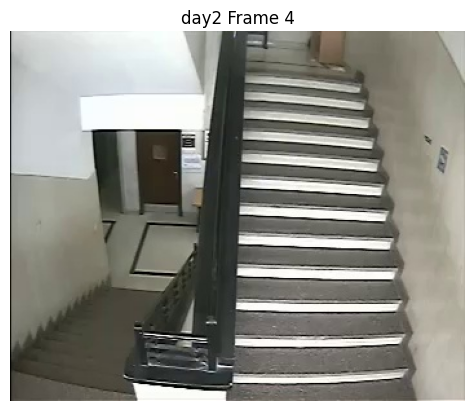

Showing frames for day3:


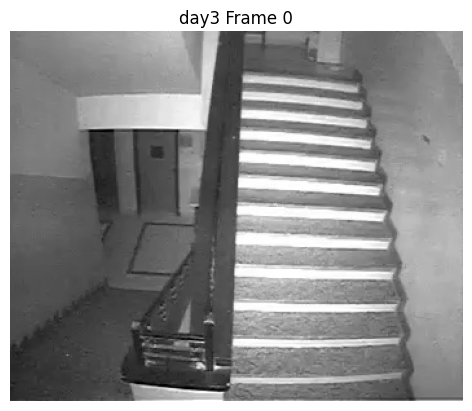

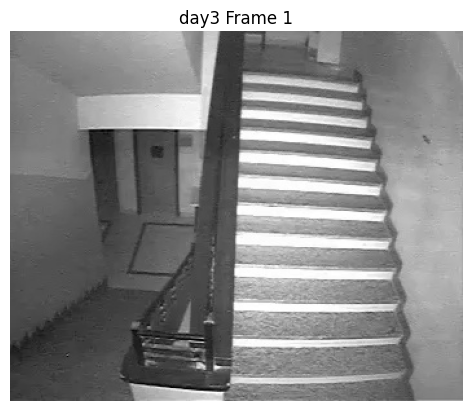

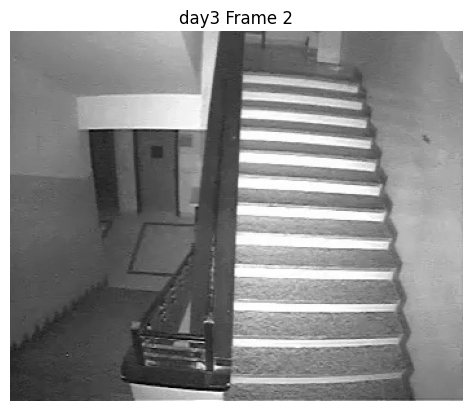

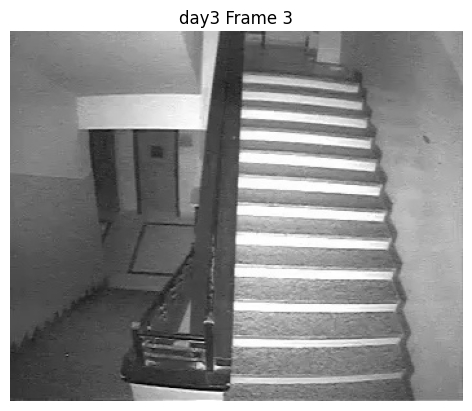

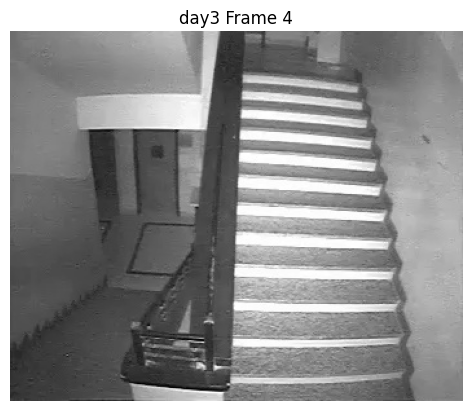

In [ ]:
video_names = ['day1', 'day2', 'day3']
output_folder = 'frames'

for vid_name in video_names:
    frames = sorted([f for f in os.listdir(output_folder) if f.startswith(vid_name)])
    print(f"Showing frames for {vid_name}:")
    for i, filename in enumerate(frames[:5]):
        frame = cv2.imread(os.path.join(output_folder, filename))
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        plt.imshow(frame_rgb)
        plt.title(f'{vid_name} Frame {i}')
        plt.axis('off')
        plt.show()


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')
output_folder = 'frames'
video_names = ['day1', 'day2', 'day3']

all_people_counts = {}

for vid_name in video_names:
    frames = sorted([f for f in os.listdir(output_folder) if f.startswith(vid_name)])
    people_counts = []
    for img in frames:
        img_path = os.path.join(output_folder, img)
        image = cv2.imread(img_path)
        results = model.predict(source=img_path, save=False, conf=0.5)
        count = 0
        for box in results[0].boxes:
            if int(box.cls[0]) == 0:  # 0: person class
                count += 1
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                conf = float(box.conf[0])
                label = f'Person {conf:.2f}'
                cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX,
                            0.5, (0, 255, 0), 2)
        people_counts.append(count)
        # Save the image with bounding boxes
        boxed_folder = 'frames_with_boxes'
        os.makedirs(boxed_folder, exist_ok=True)
        cv2.imwrite(os.path.join(boxed_folder, img), image)
    all_people_counts[vid_name] = people_counts
    print(f"Detection complete for {vid_name}. Example counts:", people_counts[:10])

Streaming output truncated to the last 5000 lines.

image 1/1 /content/frames/day2_time_390s.jpg: 544x640 (no detections), 180.4ms
Speed: 5.8ms preprocess, 180.4ms inference, 0.9ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/frames/day2_time_3930s.jpg: 544x640 (no detections), 180.8ms
Speed: 4.6ms preprocess, 180.8ms inference, 1.0ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/frames/day2_time_3960s.jpg: 544x640 (no detections), 182.9ms
Speed: 4.2ms preprocess, 182.9ms inference, 1.2ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/frames/day2_time_3990s.jpg: 544x640 1 person, 183.4ms
Speed: 5.5ms preprocess, 183.4ms inference, 1.6ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/frames/day2_time_4020s.jpg: 544x640 2 persons, 200.8ms
Speed: 5.0ms preprocess, 200.8ms inference, 1.6ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/frames/day2_time_4050s.jpg: 544x640 (no detectio

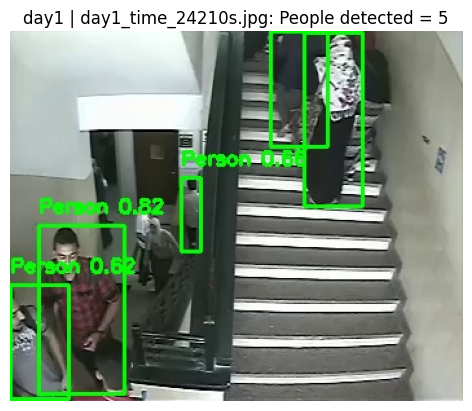

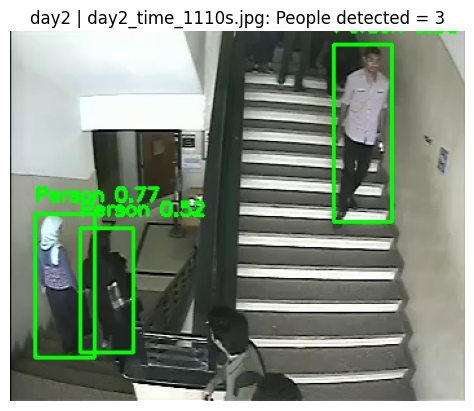

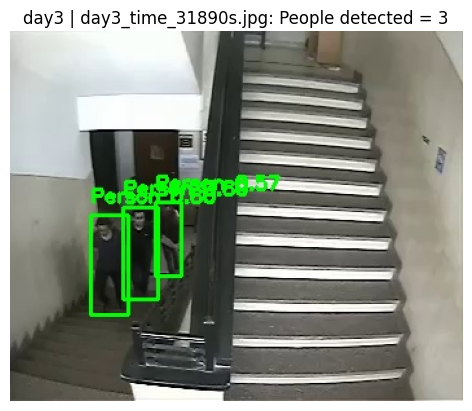

In [ ]:
video_names = ['day1', 'day2', 'day3']
for vid_name in video_names:
    frames = sorted([f for f in os.listdir(output_folder) if f.startswith(vid_name)])
    for img, count in zip(frames, all_people_counts[vid_name]):
        if count > 2:
            img_path = os.path.join(boxed_folder, img)
            image = cv2.imread(img_path)
            plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            plt.axis('off')
            plt.title(f"{vid_name} | {img}: People detected = {count}")
            plt.show()
            break



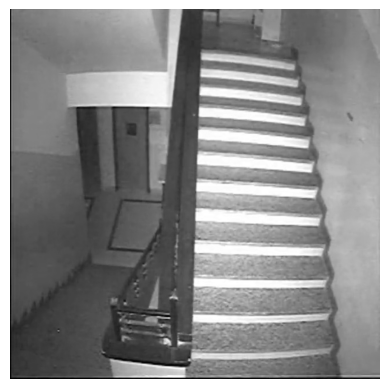

In [ ]:
# import matplotlib.pyplot as plt
# plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
# plt.axis('off')
# plt.show()

In [ ]:
import pandas as pd
from datetime import datetime, timedelta

time_series_data = []
start_date = datetime(2025, 10, 1, 7, 0, 0)  # gym opens at 7AM
interval = timedelta(seconds=10)  # frame sampling every 10 seconds

for day_idx, (day, counts) in enumerate(all_people_counts.items()):
    for i, c in enumerate(counts):
        timestamp = start_date + timedelta(days=day_idx, seconds=i * interval.seconds)
        time_series_data.append([timestamp, c])

df = pd.DataFrame(time_series_data, columns=['Datetime', 'People'])
df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.set_index('Datetime')
df = df.sort_index()

df_15min = df.resample('15T').agg(
    People_per_15min=('People', 'sum'),
    Avg=('People', 'mean')
)
df_15min = df_15min.fillna(0)

print(df_15min.head(20))


                     People_per_15min       Avg
Datetime                                       
2025-10-01 07:00:00                 0  0.000000
2025-10-01 07:15:00                 0  0.000000
2025-10-01 07:30:00                 0  0.000000
2025-10-01 07:45:00                 0  0.000000
2025-10-01 08:00:00                 4  0.044444
2025-10-01 08:15:00                64  0.711111
2025-10-01 08:30:00                60  0.666667
2025-10-01 08:45:00                16  0.177778
2025-10-01 09:00:00                 0  0.000000
2025-10-01 09:15:00                 0  0.000000
2025-10-01 09:30:00                 0  0.000000
2025-10-01 09:45:00                 0  0.000000
2025-10-01 10:00:00                 0  0.000000
2025-10-01 10:15:00                 0  0.000000
2025-10-01 10:30:00                 0  0.000000
2025-10-01 10:45:00                 0  0.000000
2025-10-01 11:00:00                 0  0.000000
2025-10-01 11:15:00                 0  0.000000
2025-10-01 11:30:00                 0  0

/tmp/ipython-input-3634402081.py:18: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  df_15min = df.resample('15T').agg(


In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
decomposition=seasonal_decompose(df_15min['People_per_15min'], period=96, extrapolate_trend=3)

In [ ]:
New_DF=df_15min.copy()
New_DF.loc[:, 'trend']=decomposition.trend
New_DF.loc[:, 'seasonal']=decomposition.seasonal
New_DF.loc[:, 'residual']=decomposition.resid

In [ ]:
New_DF

,People_per_15min,Avg,trend,seasonal,residual
Datetime,,,,,
2025-10-01 07:00:00,0,0.000000,-8.335938,10.973843,-2.637905
2025-10-01 07:15:00,0,0.000000,-8.127604,7.949016,0.178588
2025-10-01 07:30:00,0,0.000000,-7.919271,8.924190,-1.004919
2025-10-01 07:45:00,0,0.000000,-7.710938,5.566030,2.144907
2025-10-01 08:00:00,4,0.044444,-7.502604,5.874537,5.628067
...,...,...,...,...,...
2025-10-03 09:45:00,12,0.133333,-5.371354,15.367419,2.003935
2025-10-03 10:00:00,13,0.144444,-5.505208,18.675926,-0.170718
2025-10-03 10:15:00,14,0.155556,-5.639063,11.651100,7.987963


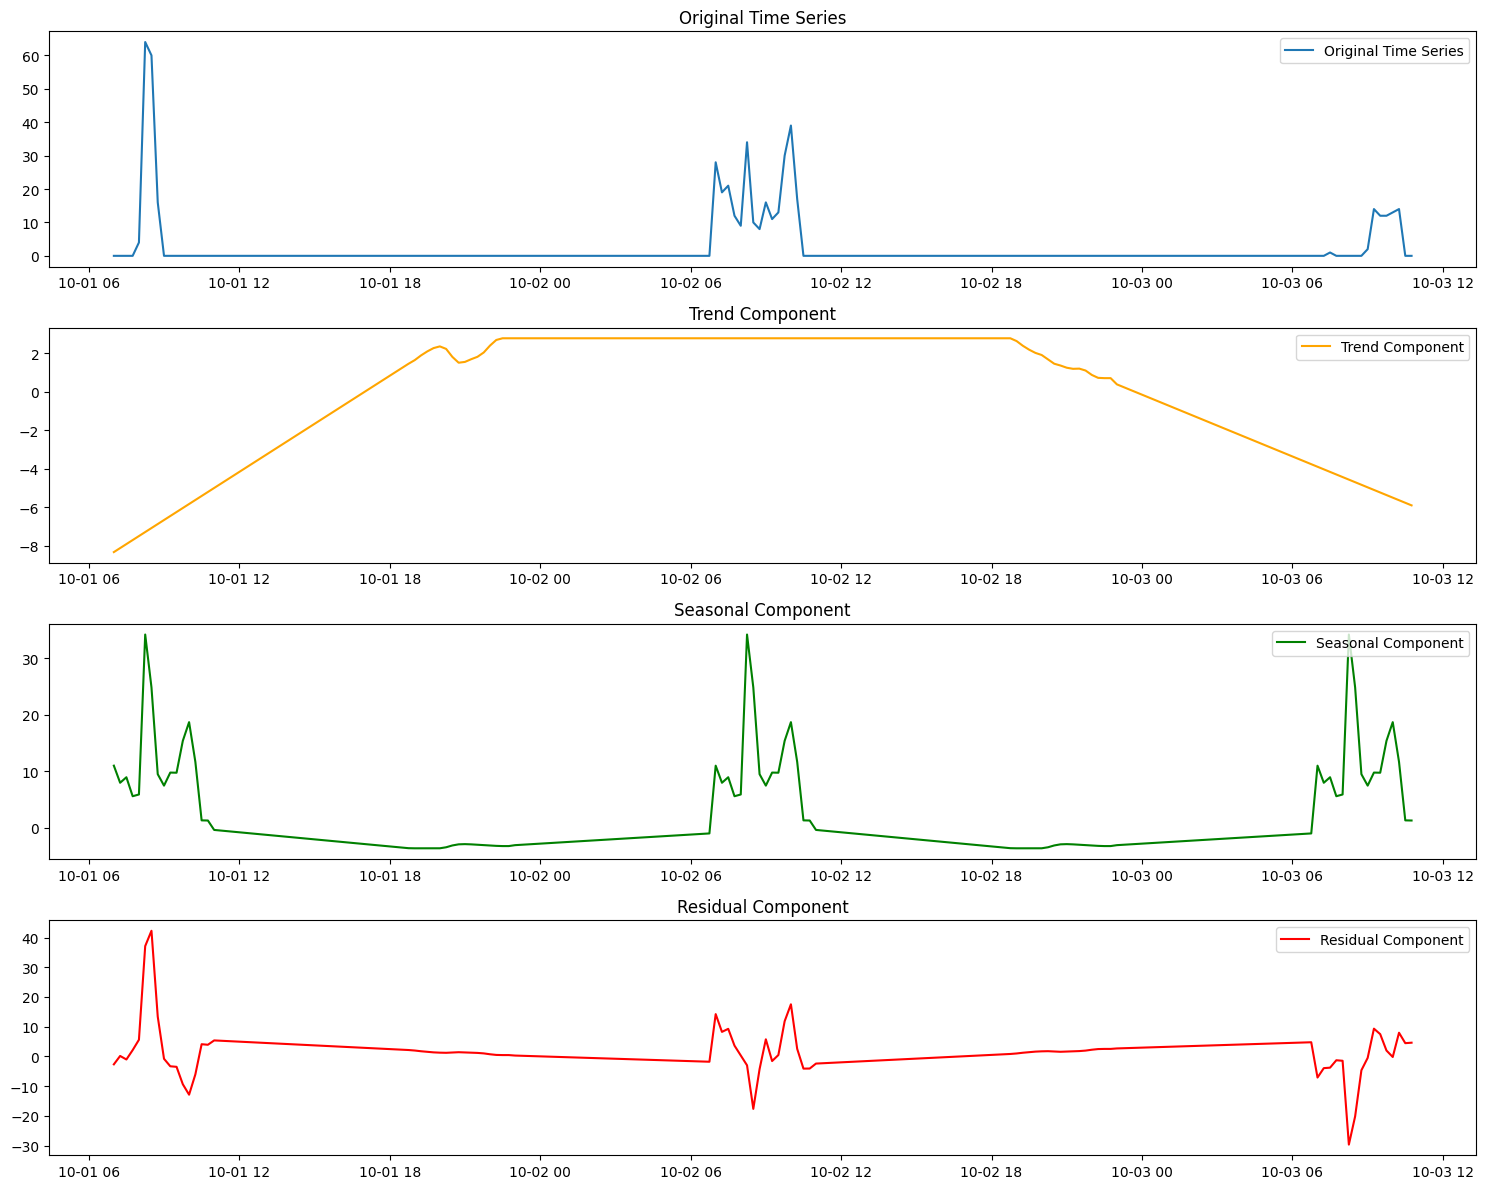

In [ ]:
plt.figure(figsize=(15, 12))
plt.subplot(4, 1, 1)
plt.plot(New_DF['People_per_15min'], label='Original Time Series')
plt.title('Original Time Series')
plt.legend()
plt.subplot(4, 1, 2)
plt.plot(New_DF['trend'], label='Trend Component', color='orange')
plt.title('Trend Component')
plt.legend()
plt.subplot(4, 1, 3)
plt.plot(New_DF['seasonal'], label='Seasonal Component', color='green')
plt.title('Seasonal Component')
plt.legend()
plt.subplot(4, 1, 4)
plt.plot(New_DF['residual'], label='Residual Component', color='red')
plt.title('Residual Component')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#Stationary Test: Dickey Fuller Test
from statsmodels.tsa.stattools import adfuller

In [ ]:
dftest=adfuller(New_DF['residual'], autolag='AIC')

In [ ]:
def test_stationarity(df_15min, People_per_15min):

  rolmean = df_15min[People_per_15min].rolling(window=12, center= False).mean()
  rolstd =  df_15min[People_per_15min].rolling(window=12, center = False).std()

  orig = plt.plot(df_15min[People_per_15min], color = 'blue', label ="Original")
  mean = plt.plot(rolmean, color ='red', label ="Rolling Mean")
  std = plt.plot(rolstd, color='black', label ="Rolling Std")
  plt.legend(loc = 'best')
  plt.title("Rolling Mean and Standard Deviation for  %s" %(People_per_15min))
  plt.xticks(rotation =45)
  plt.show(block = False)
  plt.close

  print('Results:')
  dftest = adfuller(df_15min[People_per_15min], autolag='AIC')
  dfoutput = pd.Series(dftest[0:4], index=["Test Statistic",'p=value','# Lasgs Used',' Number of Observations'])

  for key, value in dftest[4].items():
    dfoutput['Critical Value(%s)' %key]= value

  print(dfoutput)

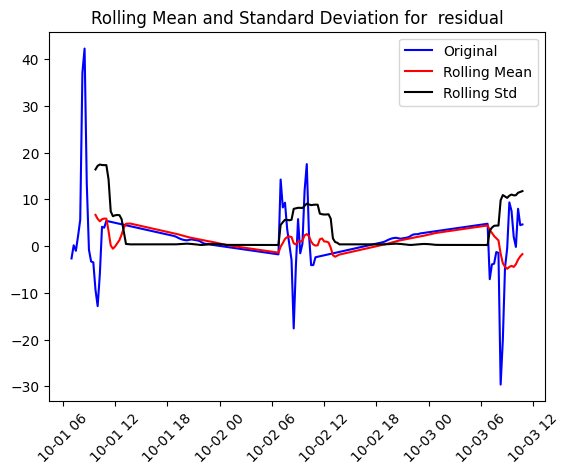

Results:
Test Statistic              -4.575436
p=value                      0.000143
# Lasgs Used                 8.000000
 Number of Observations    199.000000
Critical Value(1%)          -3.463645
Critical Value(5%)          -2.876176
Critical Value(10%)         -2.574572
dtype: float64


In [ ]:
test_stationarity(df_15min=New_DF, People_per_15min='residual')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

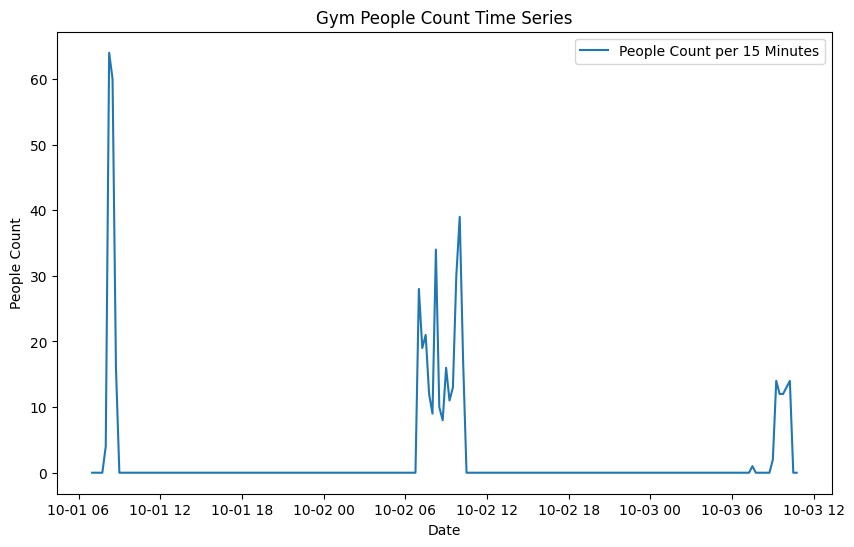

In [ ]:
time_series = df_15min['People_per_15min']
plt.figure(figsize=(10, 6))
plt.plot(time_series, label='People Count per 15 Minutes')
plt.title('Gym People Count Time Series')
plt.xlabel('Date')
plt.ylabel('People Count')
plt.legend()
plt.show()

In [ ]:
# Model Building and Forecasting
arima_model = ARIMA(time_series, order=(1, 1, 1))
arima_fit = arima_model.fit()

sarima_model = SARIMAX(time_series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 96)) # seasonal period = 96 (daily seasonality for 15-minute intervals)
sarima_fit = sarima_model.fit(disp=False)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [ ]:
forecast_steps = 96                                             # Forecast for next 24 hours (96 intervals of 15 minutes)
arima_forecast = arima_fit.get_forecast(steps=forecast_steps)
arima_forecast_series = arima_forecast.predicted_mean
arima_forecast_ci = arima_forecast.conf_int()

sarima_forecast = sarima_fit.get_forecast(steps=forecast_steps)
sarima_forecast_series = sarima_forecast.predicted_mean
sarima_forecast_ci = sarima_forecast.conf_int()

In [ ]:
# Model Evaluation.
actual = time_series[-forecast_steps:] if len(time_series) >= forecast_steps else time_series

In [ ]:
arima_mae = mean_absolute_error(actual, arima_forecast_series[:len(actual)])
arima_mse = mean_squared_error(actual, arima_forecast_series[:len(actual)])
arima_rmse = np.sqrt(arima_mse)
arima_mape = np.mean(np.abs((actual - arima_forecast_series[:len(actual)]) / actual)) * 100

sarima_mae = mean_absolute_error(actual, sarima_forecast_series[:len(actual)])
sarima_mse = mean_squared_error(actual, sarima_forecast_series[:len(actual)])
sarima_rmse = np.sqrt(sarima_mse)
sarima_mape = np.mean(np.abs((actual - sarima_forecast_series[:len(actual)]) / actual)) * 100

print(f"ARIMA MAE: {arima_mae}, MSE: {arima_mse}, RMSE: {arima_rmse}, MAPE: {arima_mape}")
print(f"SARIMA MAE: {sarima_mae}, MSE: {sarima_mse}, RMSE: {sarima_rmse}, MAPE: {sarima_mape}")

ARIMA MAE: 2.623122055587651, MSE: 10.63081578531491, RMSE: 3.2604931813017046, MAPE: nan
SARIMA MAE: 4.034271045061504, MSE: 17.04227657661438, RMSE: 4.128229230143885, MAPE: nan


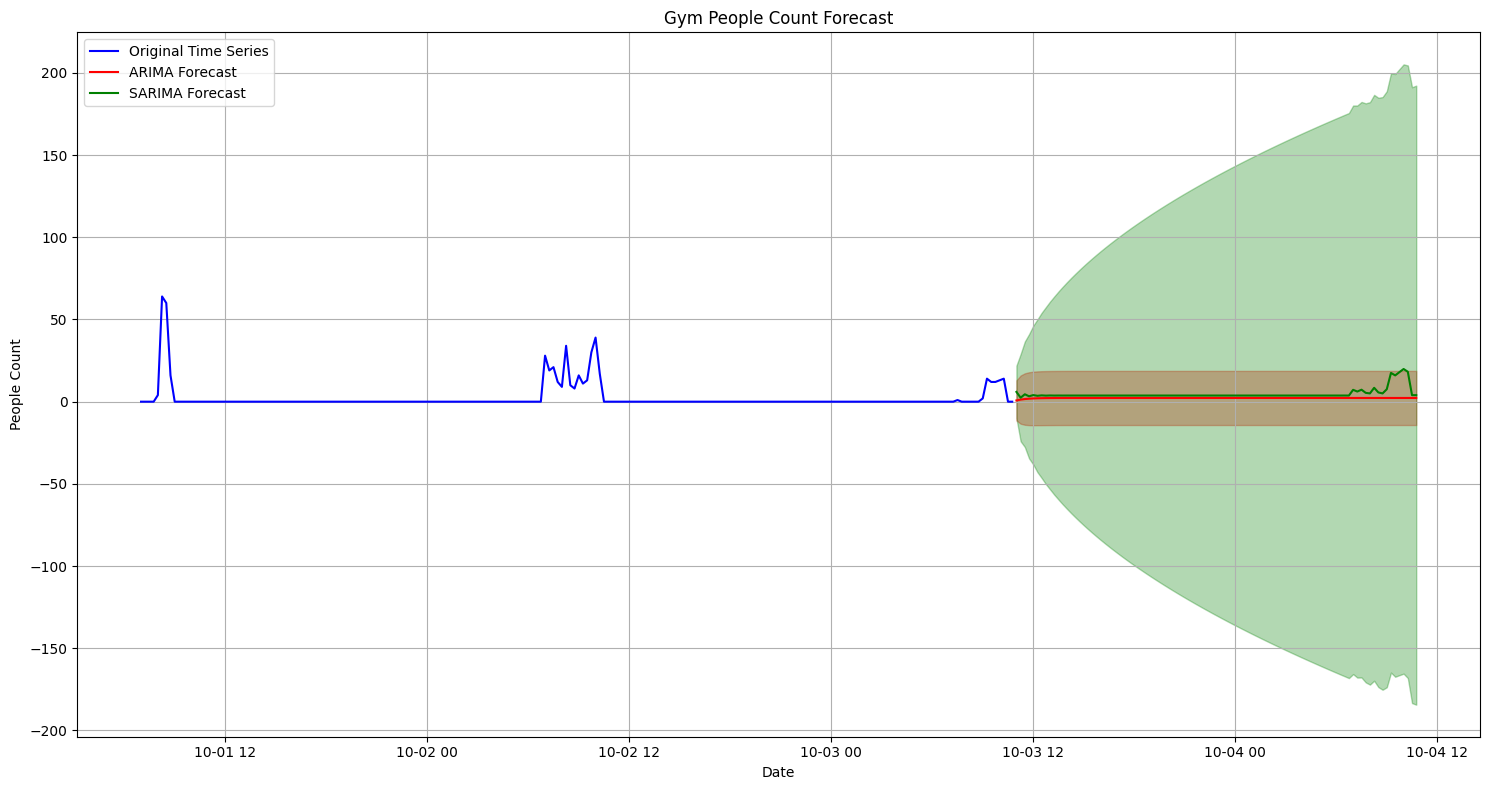

In [ ]:
# Plotting the Forecast
plt.figure(figsize=(15, 8))
plt.plot(time_series, label='Original Time Series', color='blue')
plt.plot(arima_forecast_series.index, arima_forecast_series, label='ARIMA Forecast', color='Red')
plt.plot(sarima_forecast_series.index, sarima_forecast_series, label='SARIMA Forecast', color='Green')
plt.fill_between(arima_forecast_series.index, arima_forecast_ci.iloc[:, 0], arima_forecast_ci.iloc[:, 1], color='Red', alpha=0.3)
plt.fill_between(sarima_forecast_series.index, sarima_forecast_ci.iloc[:, 0], sarima_forecast_ci.iloc[:, 1], color='Green', alpha=0.3)
plt.title('Gym People Count Forecast')
plt.xlabel('Date')
plt.ylabel('People Count')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()